# Lab — Pandas: Create, Manipulate and Save a DataFrame

## Context

You ran a **visual reaction time experiment** on 20 subjects split into two groups (controls and patients) and two experimental conditions:

| Condition | Description |
|-----------|-------------|
| **1** | Simple stimulus (circle, short duration) |
| **2** | Complex stimulus (geometric shape, long duration) |

For each subject you have:
- `subject` : subject ID (1–20)
- `age` : age in years
- `condition` : 1 or 2
- `group` : `'control'` or `'patient'`
- `reaction_time_ms` : mean reaction time (ms)
- `accuracy_pct` : mean accuracy (%)

**Lab objectives:**
1. Define Python variables (lists)
2. Build a Pandas DataFrame
3. Explore, filter and sort the data
4. Compute descriptive statistics
5. Produce plots
6. Save the DataFrame as CSV and Excel

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (11, 4)
plt.rcParams['font.size'] = 11

---
## 1. Define the variables

In Python, a **list** (`list`) is an ordered sequence of values.  
Each variable below will become **one column** of the future DataFrame.

> 💡 All lists must have **the same length** (one value per subject).

In [2]:
# ── Subject IDs ──────────────────────────────────────────────────────────────
# list(range(1, 21)) generates [1, 2, 3, ..., 20]
subjects = list(range(1, 21))

# ── Ages (in years) ──────────────────────────────────────────────────────────
ages = [24, 28, 22, 31, 26, 23, 29, 27, 25, 30,
        42, 55, 38, 47, 51, 44, 39, 52, 46, 48]

# ── Experimental condition: 1 = simple, 2 = complex ─────────────────────────
conditions = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
              2, 2, 2, 2, 2, 2, 2, 2, 2, 2]

# ── Group ────────────────────────────────────────────────────────────────────
groups = ['control', 'control', 'control', 'control', 'control',
          'patient', 'patient', 'patient', 'patient', 'patient',
          'control', 'control', 'control', 'control', 'control',
          'patient', 'patient', 'patient', 'patient', 'patient']

# ── Mean reaction time (ms) ──────────────────────────────────────────────────
RT_ms = [342.5, 361.2, 348.7, 375.1, 359.3,
         418.4, 442.0, 407.6, 461.8, 430.2,
         381.1, 375.8, 394.3, 368.9, 386.4,
         478.2, 512.4, 493.1, 505.7, 467.9]

# ── Mean accuracy (%) ────────────────────────────────────────────────────────
accuracy = [93.5, 91.0, 94.2, 92.8, 95.1,
            83.4, 79.2, 86.0, 80.5, 82.3,
            89.1, 91.4, 87.6, 90.0, 88.5,
            75.8, 71.4, 78.6, 73.9, 70.5]

# ── Check all lists have the same length ─────────────────────────────────────
columns = {'subjects': subjects, 'ages': ages, 'conditions': conditions,
           'groups': groups, 'RT_ms': RT_ms, 'accuracy': accuracy}
for name, lst in columns.items():
    print(f'{name:<12} : {len(lst)} values')

subjects     : 20 values
ages         : 20 values
conditions   : 20 values
groups       : 20 values
RT_ms        : 20 values
accuracy     : 20 values


### ❓ Questions 1

1. How many subjects are there in total? How many per condition? How many per group?
2. Look at the `conditions` list: what is the value at index 0? At index 10? *(reminder: `conditions[0]`)*
3. How do you get the **minimum** and **maximum** of the `ages` list using basic Python functions?

In [3]:
# Exercise 1: print the minimum and maximum age
# Your code here:
print('Min age:', min(ages))
print('Max age:', max(ages))

Min age: 22
Max age: 55


---
## 2. Create the DataFrame

`pd.DataFrame(dictionary)` builds a 2-D table (rows = subjects, columns = variables).  
Pass a **dictionary** `{column_name: list_of_values, ...}`.

In [38]:
# Create the DataFrame by passing a dictionary
df = pd.DataFrame({
    'subject'         : subjects,
    'age'             : ages,
    'condition'       : conditions,
    'group'           : groups,
    'reaction_time_ms': RT_ms,
    'accuracy_pct'    : accuracy,
})

print('DataFrame created:', df.shape, 'into', df.shape[0], 'rows,', df.shape[1], 'columns')
df   # display the DataFrame

DataFrame created: (20, 6) into 20 rows, 6 columns


,subject,age,condition,group,reaction_time_ms,accuracy_pct
0,1,24,1,control,342.5,93.5
1,2,28,1,control,361.2,91.0
2,3,22,1,control,348.7,94.2
3,4,31,1,control,375.1,92.8
4,5,26,1,control,359.3,95.1
5,6,23,1,patient,418.4,83.4
6,7,29,1,patient,442.0,79.2
7,8,27,1,patient,407.6,86.0
8,9,25,1,patient,461.8,80.5
9,10,30,1,patient,430.2,82.3


---
## 3. Explore the DataFrame

Before any analysis, always **inspect** your data:
- `.head(n)` → first n rows
- `.tail(n)` → last n rows
- `.shape` → dimensions (rows, columns)
- `.dtypes` → data type of each column
- `.info()` → full summary
- `.describe()` → quick descriptive statistics

In [39]:
print('── First 3 rows ──')
display(df.head(3))

print('\n── Last 3 rows ──')
display(df.tail(3))

── First 3 rows ──


,subject,age,condition,group,reaction_time_ms,accuracy_pct
0,1,24,1,control,342.5,93.5
1,2,28,1,control,361.2,91.0
2,3,22,1,control,348.7,94.2



── Last 3 rows ──


,subject,age,condition,group,reaction_time_ms,accuracy_pct
17,18,52,2,patient,493.1,78.6
18,19,46,2,patient,505.7,73.9
19,20,48,2,patient,467.9,70.5


In [40]:
print('── Column types ──')
print(df.dtypes)

print('\n── General summary ──')
df.info()

── Column types ──
subject               int64
age                   int64
condition             int64
group                   str
reaction_time_ms    float64
accuracy_pct        float64
dtype: object

── General summary ──
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   subject           20 non-null     int64  
 1   age               20 non-null     int64  
 2   condition         20 non-null     int64  
 3   group             20 non-null     str    
 4   reaction_time_ms  20 non-null     float64
 5   accuracy_pct      20 non-null     float64
dtypes: float64(2), int64(3), str(1)
memory usage: 1.1 KB


In [41]:
print('── Descriptive statistics for numeric columns ──')
df.describe().round(2)

── Descriptive statistics for numeric columns ──


,subject,age,condition,reaction_time_ms,accuracy_pct
count,20.00,20.00,20.00,20.00,20.00
mean,10.50,36.35,1.50,415.53,84.74
std,5.92,11.01,0.51,54.83,7.83
min,1.00,22.00,1.00,342.50,70.50
25%,5.75,26.75,1.00,373.55,79.05
50%,10.50,34.50,1.50,400.95,86.80
75%,15.25,46.25,2.00,463.32,91.10
max,20.00,55.00,2.00,512.40,95.10


### ❓ Questions 2

1. What is the data type of the `condition` column? Is this consistent with what it represents?
2. What does `count` indicate in `.describe()`? Is it the same for all columns?
3. What is the **median** reaction time (50%)? What is the **standard deviation** of accuracy?
4. **Exercise:** display only columns `subject`, `condition` and `group` using `df[['subject', 'condition', 'group']]`.

In [8]:
# Exercise 2a: select multiple columns
# Your code here:
df[['subject', 'condition', 'group']]

,subject,condition,group
0,1,1,control
1,2,1,control
2,3,1,control
3,4,1,control
4,5,1,control
5,6,1,patient
6,7,1,patient
7,8,1,patient
8,9,1,patient
9,10,1,patient


In [42]:
# Exercise 2b: access a single column (returns a Series)
# Complete to display the 'reaction_time_ms' column
rt_col = df['reaction_time_ms']
print(type(rt_col))     # pd.Series
print(rt_col)

<class 'pandas.Series'>
0     342.5
1     361.2
2     348.7
3     375.1
4     359.3
5     418.4
6     442.0
7     407.6
8     461.8
9     430.2
10    381.1
11    375.8
12    394.3
13    368.9
14    386.4
15    478.2
16    512.4
17    493.1
18    505.7
19    467.9
Name: reaction_time_ms, dtype: float64


---
## 4. Filter the data

**Filter** with a boolean condition inside brackets:  
```python
df[df['column'] == value]       # rows where column equals value
df[df['column'] > threshold]    # rows where column > threshold
df[(condition_A) & (condition_B)] # logical AND
df[(condition_A) | (condition_B)] # logical OR
```

In [43]:
# ── Example: subjects in condition 1 ─────────────────────────────────────────
cond1 = df[df['condition'] == 1]
print(f'Condition 1: {len(cond1)} subjects')
display(cond1)

Condition 1: 10 subjects


,subject,age,condition,group,reaction_time_ms,accuracy_pct
0,1,24,1,control,342.5,93.5
1,2,28,1,control,361.2,91.0
2,3,22,1,control,348.7,94.2
3,4,31,1,control,375.1,92.8
4,5,26,1,control,359.3,95.1
5,6,23,1,patient,418.4,83.4
6,7,29,1,patient,442.0,79.2
7,8,27,1,patient,407.6,86.0
8,9,25,1,patient,461.8,80.5
9,10,30,1,patient,430.2,82.3


In [44]:
# Exercise 3a: filter subjects in condition 2
# Your code here:
cond2 = df[df['condition'] == 2]
print(f'Condition 2: {len(cond2)} subjects')
display(cond2)

Condition 2: 10 subjects


,subject,age,condition,group,reaction_time_ms,accuracy_pct
10,11,42,2,control,381.1,89.1
11,12,55,2,control,375.8,91.4
12,13,38,2,control,394.3,87.6
13,14,47,2,control,368.9,90.0
14,15,51,2,control,386.4,88.5
15,16,44,2,patient,478.2,75.8
16,17,39,2,patient,512.4,71.4
17,18,52,2,patient,493.1,78.6
18,19,46,2,patient,505.7,73.9
19,20,48,2,patient,467.9,70.5


In [45]:
# ── Example: subjects with RT > 400 ms ───────────────────────────────────────
slow_subjects = df[df['reaction_time_ms'] > 400]
print(f'{len(slow_subjects)} subjects with RT > 400 ms:')
display(slow_subjects[['subject', 'group', 'condition', 'reaction_time_ms']])

10 subjects with RT > 400 ms:


,subject,group,condition,reaction_time_ms
5,6,patient,1,418.4
6,7,patient,1,442.0
7,8,patient,1,407.6
8,9,patient,1,461.8
9,10,patient,1,430.2
15,16,patient,2,478.2
16,17,patient,2,512.4
17,18,patient,2,493.1
18,19,patient,2,505.7
19,20,patient,2,467.9


In [46]:
# Exercise 3b: filter subjects with accuracy BELOW 85 %
# Your code here:
inaccurate = df[df['accuracy_pct'] < 85]
print(f'{len(inaccurate)} subjects with accuracy < 85 %:')
display(inaccurate[['subject', 'group', 'condition', 'accuracy_pct']])

9 subjects with accuracy < 85 %:


,subject,group,condition,accuracy_pct
5,6,patient,1,83.4
6,7,patient,1,79.2
8,9,patient,1,80.5
9,10,patient,1,82.3
15,16,patient,2,75.8
16,17,patient,2,71.4
17,18,patient,2,78.6
18,19,patient,2,73.9
19,20,patient,2,70.5


In [14]:
# ── Combined filters (AND = &) ────────────────────────────────────────────────
# Patients in condition 2 only
patients_c2 = df[(df['group'] == 'patient') & (df['condition'] == 2)]
print(f'Patients, condition 2: {len(patients_c2)} subjects')
display(patients_c2)

Patients, condition 2: 5 subjects


,subject,age,condition,group,reaction_time_ms,accuracy_pct
15,16,44,2,patient,478.2,75.8
16,17,39,2,patient,512.4,71.4
17,18,52,2,patient,493.1,78.6
18,19,46,2,patient,505.7,73.9
19,20,48,2,patient,467.9,70.5


In [15]:
# Exercise 3c: select CONTROLS with accuracy >= 90 %
# Your code here:
accurate_ctrl = df[(df['group'] == 'control') & (df['accuracy_pct'] >= 90)]
print(f'Controls with accuracy >= 90 %: {len(accurate_ctrl)} subjects')
display(accurate_ctrl)

Controls with accuracy >= 90 %: 7 subjects


,subject,age,condition,group,reaction_time_ms,accuracy_pct
0,1,24,1,control,342.5,93.5
1,2,28,1,control,361.2,91.0
2,3,22,1,control,348.7,94.2
3,4,31,1,control,375.1,92.8
4,5,26,1,control,359.3,95.1
11,12,55,2,control,375.8,91.4
13,14,47,2,control,368.9,90.0


### ❓ Questions 3

1. Why do you need parentheses around each condition when using `&` or `|`?
2. How do you select subjects that are either in condition 1 **or** controls (logical OR)?
3. What does `df[df['group'] == 'patient']['subject']` return? What Python type is it?

In [16]:
# Exercise 3d: OR logic — subjects in condition 1 OR older than 45
# Your code here:
sel_or = df[(df['condition'] == 1) | (df['age'] > 45)]
print(f'{len(sel_or)} subjects selected')
display(sel_or[['subject', 'age', 'condition', 'group']])

16 subjects selected


,subject,age,condition,group
0,1,24,1,control
1,2,28,1,control
2,3,22,1,control
3,4,31,1,control
4,5,26,1,control
5,6,23,1,patient
6,7,29,1,patient
7,8,27,1,patient
8,9,25,1,patient
9,10,30,1,patient


---
## 5. Sort, add and transform columns

| Method | Description |
|--------|-------------|
| `.sort_values('col')` | Sort by a column (ascending) |
| `.sort_values('col', ascending=False)` | Sort descending |
| `df['new_col'] = expr` | Add / update a column |
| `.apply(lambda x: ...)` | Apply a function to each value |

In [17]:
# ── Sort by reaction time (descending) ───────────────────────────────────────
df_sorted = df.sort_values('reaction_time_ms', ascending=False)
print('5 slowest subjects:')
display(df_sorted[['subject', 'group', 'condition', 'reaction_time_ms']].head(5))

5 slowest subjects:


,subject,group,condition,reaction_time_ms
16,17,patient,2,512.4
18,19,patient,2,505.7
17,18,patient,2,493.1
15,16,patient,2,478.2
19,20,patient,2,467.9


In [18]:
# Exercise 4a: sort by accuracy from LOWEST to HIGHEST
# Your code here:
df_acc = df.sort_values('accuracy_pct', ascending=True)
print('5 least accurate subjects:')
display(df_acc[['subject', 'group', 'condition', 'accuracy_pct']].head(5))

5 least accurate subjects:


,subject,group,condition,accuracy_pct
19,20,patient,2,70.5
16,17,patient,2,71.4
18,19,patient,2,73.9
15,16,patient,2,75.8
17,18,patient,2,78.6


In [19]:
# ── Add a derived column ──────────────────────────────────────────────────────
# Convert ms to seconds
df['reaction_time_s'] = (df['reaction_time_ms'] / 1000).round(4)

print('New column added:', df.columns.tolist())
df[['subject', 'reaction_time_ms', 'reaction_time_s']].head(4)

New column added: ['subject', 'age', 'condition', 'group', 'reaction_time_ms', 'accuracy_pct', 'reaction_time_s']


,subject,reaction_time_ms,reaction_time_s
0,1,342.5,0.3425
1,2,361.2,0.3612
2,3,348.7,0.3487
3,4,375.1,0.3751


In [20]:
# ── Categorical column with apply + lambda ────────────────────────────────────
# 'high' if accuracy >= 90 %, 'low' otherwise
df['performance'] = df['accuracy_pct'].apply(
    lambda x: 'high' if x >= 90 else 'low'
)

print('Performance distribution:')
print(df['performance'].value_counts())
print()
df[['subject', 'accuracy_pct', 'performance']].head(8)

Performance distribution:
performance
low     13
high     7
Name: count, dtype: int64



,subject,accuracy_pct,performance
0,1,93.5,high
1,2,91.0,high
2,3,94.2,high
3,4,92.8,high
4,5,95.1,high
5,6,83.4,low
6,7,79.2,low
7,8,86.0,low


In [21]:
# Exercise 4b: create an 'age_group' column: 'young' (< 35) or 'adult' (>= 35)
# Your code here:
df['age_group'] = df['age'].apply(lambda x: 'young' if x < 35 else 'adult')

print('Age group distribution:')
print(df['age_group'].value_counts())

Age group distribution:
age_group
young    10
adult    10
Name: count, dtype: int64


---
## 6. Descriptive statistics

| Method | Result |
|--------|--------|
| `.mean()` | Mean |
| `.std()` | Standard deviation |
| `.median()` | Median |
| `.min()` / `.max()` | Min / Max |
| `.value_counts()` | Count of unique values |
| `.groupby('col').agg(...)` | Statistics **per group** |

In [22]:
# ── Global statistics on RT ───────────────────────────────────────────────────
print('Reaction time (ms) — global statistics')
print(f'  Mean      : {df["reaction_time_ms"].mean():.1f}')
print(f'  Median    : {df["reaction_time_ms"].median():.1f}')
print(f'  Std dev   : {df["reaction_time_ms"].std():.1f}')
print(f'  Min / Max : {df["reaction_time_ms"].min():.1f} / {df["reaction_time_ms"].max():.1f}')

Reaction time (ms) — global statistics
  Mean      : 415.5
  Median    : 401.0
  Std dev   : 54.8
  Min / Max : 342.5 / 512.4


In [23]:
# ── Statistics by condition (manual filter) ───────────────────────────────────
for cond in [1, 2]:
    subset = df[df['condition'] == cond]
    print(f'Condition {cond}  ({len(subset)} subjects)')
    print(f'  Mean RT       : {subset["reaction_time_ms"].mean():.1f} ms')
    print(f'  Mean accuracy : {subset["accuracy_pct"].mean():.1f} %')
    print()

Condition 1  (10 subjects)
  Mean RT       : 394.7 ms
  Mean accuracy : 87.8 %

Condition 2  (10 subjects)
  Mean RT       : 436.4 ms
  Mean accuracy : 81.7 %



In [24]:
# ── groupby: automatic calculation per group ──────────────────────────────────
# .agg() applies several functions at once
stats_cond = (
    df.groupby('condition')['reaction_time_ms']
      .agg(['mean', 'std', 'median', 'min', 'max'])
      .round(1)
)
stats_cond.index = ['Condition 1', 'Condition 2']
stats_cond.columns = ['Mean', 'Std dev', 'Median', 'Min', 'Max']
print('RT (ms) by condition:')
stats_cond

RT (ms) by condition:


,Mean,Std dev,Median,Min,Max
Condition 1,394.7,42.6,391.4,342.5,461.8
Condition 2,436.4,59.7,431.1,368.9,512.4


In [25]:
# Exercise 5a: compute mean and std of accuracy by GROUP
# Your code here:
stats_grp = (
    df.groupby('group')['accuracy_pct']
      .agg(['mean', 'std'])
      .round(2)
)
stats_grp.columns = ['Mean accuracy (%)', 'Std dev (%)']
stats_grp

,Mean accuracy (%),Std dev (%)
group,,
control,91.32,2.54
patient,78.16,5.17


In [26]:
# ── Double groupby: condition × group ─────────────────────────────────────────
pivot = (
    df.groupby(['group', 'condition'])['reaction_time_ms']
      .mean()
      .round(1)
      .unstack('condition')   # put 'condition' as columns
)
pivot.columns = ['Cond. 1 (ms)', 'Cond. 2 (ms)']
print('Mean RT by group × condition:')
pivot

Mean RT by group × condition:


,Cond. 1 (ms),Cond. 2 (ms)
group,,
control,357.4,381.3
patient,432.0,491.5


In [27]:
# ── value_counts: count occurrences in a categorical column ───────────────────
print('Distribution by group:')
print(df['group'].value_counts())

print()
print('Distribution by group AND condition:')
print(df.groupby(['group', 'condition']).size())

Distribution by group:
group
control    10
patient    10
Name: count, dtype: int64

Distribution by group AND condition:
group    condition
control  1            5
         2            5
patient  1            5
         2            5
dtype: int64


### ❓ Questions 4

1. Looking at the `pivot` table, which condition produces the longest RTs? Is the difference larger for patients or controls?
2. Using `groupby`, compute the **mean age** by age group (`age_group`). Check that the result is consistent.
3. What is the difference between `df.describe()` and `df.groupby('condition').describe()`?

In [36]:
# Exercise 5b: compute mean age by age group
# Your code here:
df.groupby('age_group')['age'].agg(['mean', 'min', 'max']).round(1)

,mean,min,max
age_group,,,
adult,46.2,38,55
young,26.5,22,31


---
## 7. Plots

Three essential plot types:
- **Histogram**: distribution of a continuous variable
- **Boxplot**: distribution + median + outliers, by category
- **Scatter plot**: relationship between two continuous variables
- **Bar chart**: compare means across groups

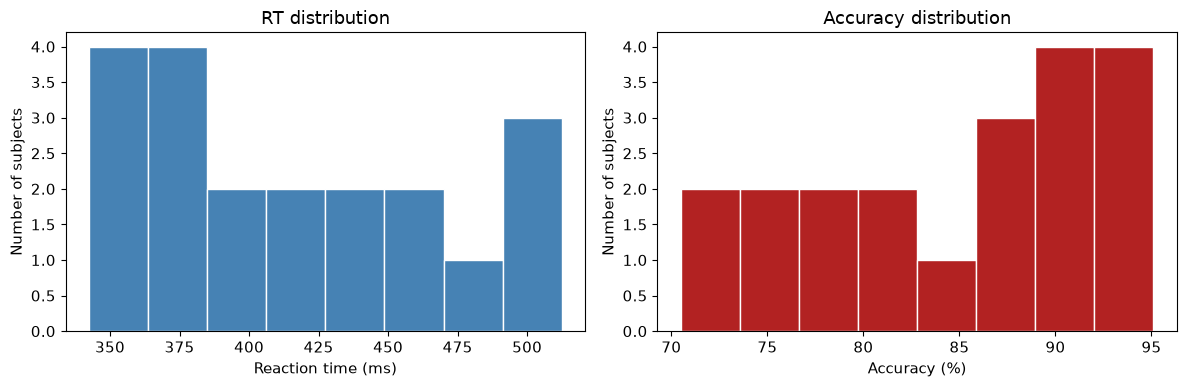

In [29]:
# ── Histograms ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['reaction_time_ms'], bins=8, color='steelblue', edgecolor='white')
axes[0].set_xlabel('Reaction time (ms)')
axes[0].set_ylabel('Number of subjects')
axes[0].set_title('RT distribution')

# Exercise 6a: plot the accuracy histogram in axes[1]
# Your code here:
axes[1].hist(df['accuracy_pct'], bins=8, color='firebrick', edgecolor='white')
axes[1].set_xlabel('Accuracy (%)')
axes[1].set_ylabel('Number of subjects')
axes[1].set_title('Accuracy distribution')

plt.tight_layout()
plt.show()

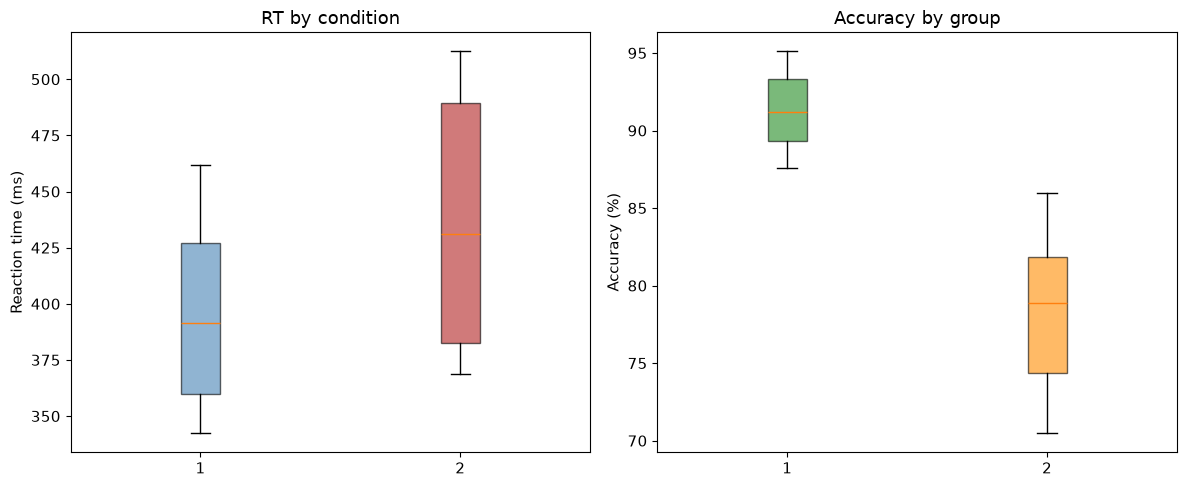

In [34]:
# ── Boxplots: RT by condition ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

data_box = [df[df['condition'] == 1]['reaction_time_ms'],
            df[df['condition'] == 2]['reaction_time_ms']]

bp = axes[0].boxplot(data_box,
                    patch_artist=True)
for patch, color in zip(bp['boxes'], ['steelblue', 'firebrick']):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
axes[0].set_ylabel('Reaction time (ms)')
axes[0].set_title('RT by condition')

# Exercise 6b: boxplot of accuracy by GROUP in axes[1]
# Your code here:
data_grp = [df[df['group'] == 'control']['accuracy_pct'],
            df[df['group'] == 'patient']['accuracy_pct']]
bp2 = axes[1].boxplot(data_grp,
                      patch_artist=True)
for patch, color in zip(bp2['boxes'], ['forestgreen', 'darkorange']):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('Accuracy by group')

plt.tight_layout()
plt.show()

In [ ]:
# ── Scatter plot: age vs RT, coloured by condition ────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))

cond_colors = {1: 'steelblue', 2: 'firebrick'}
for cond, sub_df in df.groupby('condition'):
    ax.scatter(sub_df['age'], sub_df['reaction_time_ms'],
               label=f'Condition {cond}',
               color=cond_colors[cond], s=80, alpha=0.85)

ax.set_xlabel('Age (years)')
ax.set_ylabel('Reaction time (ms)')
ax.set_title('Age vs Reaction time')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Exercise 6c: scatter plot of RT vs accuracy, coloured by GROUP
# Your code here:
fig, ax = plt.subplots(figsize=(8, 5))

grp_colors = {'control': 'forestgreen', 'patient': 'darkorange'}
for grp_name, sub_df in df.groupby('group'):
    ax.scatter(sub_df['reaction_time_ms'], sub_df['accuracy_pct'],
               label=grp_name, color=grp_colors[grp_name], s=80, alpha=0.85)

ax.set_xlabel('Reaction time (ms)')
ax.set_ylabel('Accuracy (%)')
ax.set_title('RT vs Accuracy by group')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# ── Bar chart: mean RT by group × condition ───────────────────────────────────
pivot_plot = (
    df.groupby(['group', 'condition'])['reaction_time_ms']
      .mean().round(1).unstack('condition')
)
pivot_plot.columns = ['Condition 1', 'Condition 2']

fig, ax = plt.subplots(figsize=(8, 5))
pivot_plot.plot.bar(ax=ax, rot=0, color=['steelblue', 'firebrick'],
                    alpha=0.8, edgecolor='white', width=0.6)

ax.set_xlabel('Group')
ax.set_ylabel('Mean RT (ms)')
ax.set_title('Mean reaction time by group and condition')
ax.legend(title='Condition')
plt.tight_layout()
plt.show()

### ❓ Questions 5

1. Looking at the scatter plot (age vs RT), is there a visible trend? What is it?
2. From the boxplot, which condition shows the most variability (large spread) in RT?
3. **Exercise:** modify the age/RT scatter plot to use **different markers** by group (`marker='o'` for control, `marker='s'` for patient).

In [ ]:
# Exercise 6d: age vs RT with different markers per group
# Your code here:
fig, ax = plt.subplots(figsize=(8, 5))
markers = {'control': 'o', 'patient': 's'}
for grp_name, sub_df in df.groupby('group'):
    ax.scatter(sub_df['age'], sub_df['reaction_time_ms'],
               label=grp_name, marker=markers[grp_name], s=90, alpha=0.85)
ax.set_xlabel('Age (years)')
ax.set_ylabel('RT (ms)')
ax.set_title('Age vs RT — shape = group')
ax.legend()
plt.tight_layout()
plt.show()

---
## 8. Save the DataFrame

| Format | Method | Reload |
|--------|--------|--------|
| CSV | `df.to_csv('file.csv', index=False)` | `pd.read_csv('file.csv')` |
| Excel | `df.to_excel('file.xlsx', index=False)` | `pd.read_excel('file.xlsx')` |

> `index=False` prevents saving the Pandas numeric index (0, 1, 2…) as an extra column.

In [ ]:
# ── Save as CSV ───────────────────────────────────────────────────────────────
csv_file = 'data_reaction_time.csv'
df.to_csv(csv_file, index=False, encoding='utf-8-sig')
print(f'CSV file saved: {csv_file}')

# Verify: reload the file
df_csv = pd.read_csv(csv_file)
print(f'Reloaded: {df_csv.shape[0]} rows, {df_csv.shape[1]} columns')
df_csv.head(3)

In [ ]:
# ── Save as Excel ─────────────────────────────────────────────────────────────
# Requires: pip install openpyxl
try:
    xlsx_file = 'data_reaction_time.xlsx'
    df.to_excel(xlsx_file, index=False, sheet_name='data')
    print(f'Excel file saved: {xlsx_file}')

    df_xlsx = pd.read_excel(xlsx_file)
    print(f'Reloaded: {df_xlsx.shape[0]} rows, {df_xlsx.shape[1]} columns')
    display(df_xlsx.head(3))
except ModuleNotFoundError:
    print('openpyxl not installed. Run: pip install openpyxl')

In [ ]:
# Exercise 7: save a SUBSET — patients only — to a separate file
# Your code here:
df_patients = df[df['group'] == 'patient']

# CSV
df_patients.to_csv('data_patients.csv', index=False)
print(f'CSV patients: {len(df_patients)} rows saved')

# Excel (if available)
try:
    df_patients.to_excel('data_patients.xlsx', index=False, sheet_name='patients')
    print('Excel patients saved.')
except:
    pass

In [ ]:
# ── Save multiple sheets in a single Excel file ───────────────────────────────
try:
    with pd.ExcelWriter('data_by_condition.xlsx', engine='openpyxl') as writer:
        df[df['condition'] == 1].to_excel(writer, sheet_name='Condition_1', index=False)
        df[df['condition'] == 2].to_excel(writer, sheet_name='Condition_2', index=False)
    print('Multi-sheet file saved: data_by_condition.xlsx')
except ModuleNotFoundError:
    print('openpyxl not installed.')

### ❓ Questions 6

1. What is the difference between `to_csv` with `index=True` and `index=False`? Open both files in a text editor to see.
2. Why use `encoding='utf-8-sig'` for CSV? What does it change when opening in Excel?
3. **Exercise:** reload `data_patients.csv` and verify you only have patients using `value_counts()`.

In [ ]:
# Exercise 7b: reload and verify the patients CSV
# Your code here:
check = pd.read_csv('data_patients.csv')
print('Groups in the reloaded file:')
print(check['group'].value_counts())
print(f'\n{len(check)} rows, {check.shape[1]} columns')

---
## Summary

| Step | Key Pandas methods |
|------|--------------------|
| Create | `pd.DataFrame({...})` |
| Explore | `.head()` `.shape` `.dtypes` `.info()` `.describe()` |
| Select | `df['col']` `df[['c1','c2']]` |
| Filter | `df[df['col'] == val]` `&` `\|` |
| Sort | `.sort_values('col', ascending=...)` |
| Transform | `df['new'] = expr` `.apply(lambda ...)` |
| Statistics | `.mean()` `.std()` `.median()` `.value_counts()` |
| Group | `.groupby('col').agg([...])` `.unstack()` |
| Plot | `plt.hist()` `.boxplot()` `.scatter()` `.plot.bar()` |
| Save | `.to_csv()` `.to_excel()` `pd.ExcelWriter` |
| Reload | `pd.read_csv()` `pd.read_excel()` |

### Final exercise

Using the DataFrame `df`, answer the following questions **in one or two lines of code**:

1. Which subject has the **shortest reaction time**? *(hint: `.sort_values().head(1)`)*
2. What is the **median accuracy** of patients in condition 2?
3. Create a `df_summary` DataFrame containing the mean RT and mean accuracy for each group × condition combination, and save it as a CSV.

In [ ]:
# Final exercise — Your code here:

# 1. Fastest subject
print('Fastest subject:')
display(df.sort_values('reaction_time_ms').head(1)[['subject', 'group', 'condition', 'reaction_time_ms']])

# 2. Median accuracy of patients in condition 2
med = df[(df['group'] == 'patient') & (df['condition'] == 2)]['accuracy_pct'].median()
print(f'\nMedian accuracy — patients / condition 2: {med} %')

# 3. Summary DataFrame
df_summary = (
    df.groupby(['group', 'condition'])
      .agg(mean_RT=('reaction_time_ms', 'mean'),
           mean_accuracy=('accuracy_pct', 'mean'))
      .round(2)
      .reset_index()
)
df_summary.to_csv('data_summary.csv', index=False)
print('\nSummary table saved.')
df_summary